# Departure Delay Models: Random Forest (classification) + Linear Regression

| | Question | Target | Model | Metrics |
|---|---|---|---|---|
| Part 1 | Will a flight depart 15+ minutes late? | `DEP_DEL15` | Random Forest | ROC-AUC, accuracy, precision, recall |
| Part 2 | How many minutes late will it depart? | `DEP_DELAY` | Linear Regression | RMSE, MAE, R² |

**Setup (standardized across models)**
- Targets and other outcome columns (`CANCELLED`, delay minutes, actual times, ...) are never used as features.
- Features: only schedule info known before departure, i.e. calendar, schedule and route. Both parts use the same feature set.
- Validation: expanding-window time-series CV. Train on Jan→validate Feb, ..., Jan–Apr→validate May; final model trained on Jan–May and **tested on Jun**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import plot_tree
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)

RANDOM_STATE = 42

## Load data

In [2]:
FILE = "flights_data.csv"
TARGET = "DEP_DEL15"       # Part 1: classification
REG_TARGET = "DEP_DELAY"    # Part 2: regression (minutes; early departures are negative)

raw_cols = ["MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK",
            "CRS_DEP_TIME", "CRS_ARR_TIME", "DEP_TIME_BLK", "CRS_ELAPSED_TIME",
            "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "DISTANCE",
            TARGET, REG_TARGET, "CANCELLED"]

df = pd.read_csv(FILE, usecols=raw_cols)
print(df.shape)
df.head()

(3488373, 14)


,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,DEP_DEL15,DEP_TIME_BLK,CRS_ARR_TIME,CANCELLED,CRS_ELAPSED_TIME,DISTANCE
0,1,1,4,AA,LAX,BOS,1358,85.0,1.0,1300-1359,2229,0.0,331.0,2611.0
1,1,1,4,AA,JFK,LAX,941,71.0,1.0,0900-0959,1303,0.0,382.0,2475.0
2,1,1,4,AA,LAX,BOS,2200,27.0,1.0,2200-2259,628,0.0,328.0,2611.0
3,1,1,4,AA,JFK,LAX,1745,1.0,0.0,1700-1759,2100,0.0,375.0,2475.0
4,1,1,4,AA,LAX,JFK,830,0.0,0.0,0800-0859,1654,0.0,324.0,2475.0


## Cleaning

- `DEP_DEL15` and `DEP_DELAY` are missing for exactly the same rows: flights cancelled before departure. Both targets are undefined for those, so we drop those rows. `CANCELLED` is only used for this check and is never a feature.
- `dep_hour` / `arr_hour` come from the *scheduled* times (`CRS_*`), so there's no leakage. `CRS_ARR_TIME` = 2400 becomes hour 0.
- `CRS_ELAPSED_TIME` has 2 missing values. sklearn ≥ 1.4 random forests handle NaN natively, so we leave them as-is.

In [3]:
print("missing target by CANCELLED:")
print(pd.crosstab(df["CANCELLED"], df[TARGET].isna()), "\n")

assert (df[TARGET].isna() == df[REG_TARGET].isna()).all()
df = df.dropna(subset=[TARGET])
df[TARGET] = df[TARGET].astype(int)

df["dep_hour"] = df["CRS_DEP_TIME"] // 100 % 24
df["arr_hour"] = df["CRS_ARR_TIME"] // 100 % 24

print("rows:", len(df), " positive rate:", round(df[TARGET].mean(), 3))
missing = df.isna().sum()
missing[missing > 0]

missing target by CANCELLED:
DEP_DEL15    False  True 
CANCELLED                
0.0        3412291      0
1.0           2235  73847 

rows: 3414526  positive rate: 0.226


CRS_ELAPSED_TIME    2
dtype: int64

# Part 1 — Random Forest classification (`DEP_DEL15`)

## Features & encoding

| Group | Features |
|---|---|
| Calendar | `DAY_OF_WEEK` |
| Schedule | `dep_hour`, `arr_hour`, `DEP_TIME_BLK`, `CRS_ELAPSED_TIME` |
| Route | `OP_UNIQUE_CARRIER`, `ORIGIN`, `DEST`, `DISTANCE` |

**Dropped calendar features:**
- `MONTH`: with expanding-window CV, the validation month never appears in training. The trees can only treat it as "later than anything seen", so it has nothing real to learn from.
- `DAY_OF_MONTH`: it hurts every fold (see the ablation below). The trees use it to memorize specific bad days in the training months, and that doesn't carry over to a new month.

**Excluded on purpose (leakage):** `DEP_TIME`, `DEP_DELAY*`, `TAXI_OUT`, `WHEELS_*`, all `ARR_*` outcomes, delay-cause columns, `CANCELLED`, `DIVERTED`.

**Encoding:** a random forest doesn't need one-hot encoding. `ORIGIN`/`DEST` have ~356 levels each, which would explode one-hot. Instead the categorical columns are **ordinal-encoded**, and the encoder is **fit on each training fold only**. Any carrier or airport not seen in training gets code `-1`. `DEP_TIME_BLK` sorts chronologically ("0600-0659" < "0700-0759"), so its codes keep the time order.

In [4]:
CATEGORICAL = ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "DEP_TIME_BLK"]
FEATURES = ["DAY_OF_WEEK",
            "dep_hour", "arr_hour", "DEP_TIME_BLK", "CRS_ELAPSED_TIME",
            "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "DISTANCE"]

def make_xy(train, valid, features=FEATURES):
    """Encode categoricals using the training fold only (no leakage into validation)."""
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X_train, X_valid = train[features].copy(), valid[features].copy()
    X_train[CATEGORICAL] = enc.fit_transform(X_train[CATEGORICAL])
    X_valid[CATEGORICAL] = enc.transform(X_valid[CATEGORICAL])
    return X_train, train[TARGET], X_valid, valid[TARGET], enc

## Time-series CV splits

Folds 1–4 are **validation** folds, used for tuning. Fold 5 (Jun) is the held-out **test** fold and is never used to choose hyperparameters.

In [5]:
SPLITS = [
    ([1],             2),   # train Jan        -> validate Feb
    ([1, 2],          3),   # train Jan-Feb    -> validate Mar
    ([1, 2, 3],       4),   # train Jan-Mar    -> validate Apr
    ([1, 2, 3, 4],    5),   # train Jan-Apr    -> validate May
    ([1, 2, 3, 4, 5], 6),   # train Jan-May    -> TEST on Jun
]
CV_SPLITS, TEST_SPLIT = SPLITS[:4], SPLITS[4]

THRESHOLD = 0.5   # class_weight="balanced_subsample" makes 0.5 a sensible cut-off

def evaluate(y_true, prob, threshold=THRESHOLD):
    pred = (prob >= threshold).astype(int)
    return {
        "ROC_AUC":   roc_auc_score(y_true, prob),
        "accuracy":  accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred),
        "recall":    recall_score(y_true, pred),
        "F1":        f1_score(y_true, pred),
    }

def fit_rf(X, y, **params):
    return RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE, **params).fit(X, y)

def split(train_months, valid_month):
    return df[df["MONTH"].isin(train_months)], df[df["MONTH"] == valid_month]

## Feature ablation: with vs. without `DAY_OF_MONTH`

Both feature sets are trained on every fold with the same reference parameters. We decide on the Feb–May CV mean; Jun is shown only for reference.

In [6]:
REF_PARAMS = dict(n_estimators=100, class_weight="balanced_subsample", max_samples=0.25,
                  max_features="sqrt", min_samples_leaf=20, max_depth=20)

ablation = {}
for name, feats in [("with DAY_OF_MONTH", ["DAY_OF_MONTH"] + FEATURES), ("without DAY_OF_MONTH", FEATURES)]:
    aucs = {}
    for train_months, valid_month in SPLITS:
        X_tr, y_tr, X_va, y_va, _ = make_xy(*split(train_months, valid_month), features=feats)
        aucs[valid_month] = roc_auc_score(y_va, fit_rf(X_tr, y_tr, **REF_PARAMS).predict_proba(X_va)[:, 1])
    ablation[name] = aucs

ablation = pd.DataFrame(ablation)
ablation.index.name = "eval_month"
ablation.loc["CV mean (Feb-May)"] = ablation.loc[2:5].mean()
ablation.round(4)

,with DAY_OF_MONTH,without DAY_OF_MONTH
eval_month,,
2,0.6265,0.6512
3,0.6385,0.6733
4,0.6658,0.6813
5,0.6845,0.6971
6,0.7158,0.7249
CV mean (Feb-May),0.6538,0.6757


In [7]:
# Pre-split once so tuning doesn't redo the encoding for every config
folds = []
for train_months, valid_month in SPLITS:
    folds.append((train_months, valid_month, *make_xy(*split(train_months, valid_month))))

## Hyperparameter tuning (on validation folds Feb–May only)

Fixed for every model:
- `n_estimators=100`
- `class_weight="balanced_subsample"`: about 22% of flights are delayed, so without reweighting the forest mostly predicts "on time".
- `max_samples=0.25`: each tree is bootstrapped from 25% of the training rows. That keeps training on ~2.8M rows fast and also de-correlates the trees.

Grid searched: `max_features` × `min_samples_leaf` × `max_depth`. We pick the config with the best **mean CV ROC-AUC**.

In [8]:
BASE_PARAMS = dict(n_estimators=100, class_weight="balanced_subsample", max_samples=0.25)

GRID = [
    dict(max_features=mf, min_samples_leaf=leaf, max_depth=depth)
    for mf in ["sqrt", 0.5]
    for leaf in [20, 100]
    for depth in [None, 20]
]

tuning_rows = []
for params in GRID:
    aucs = []
    for train_months, valid_month, X_tr, y_tr, X_va, y_va, _ in folds[:4]:
        model = fit_rf(X_tr, y_tr, **BASE_PARAMS, **params)
        aucs.append(roc_auc_score(y_va, model.predict_proba(X_va)[:, 1]))
    tuning_rows.append({**params, **{f"AUC_m{m}": a for (_, m), a in zip(CV_SPLITS, aucs)},
                        "mean_CV_AUC": np.mean(aucs)})
    print(params, "mean CV AUC:", round(np.mean(aucs), 4))

tuning = pd.DataFrame(tuning_rows).sort_values("mean_CV_AUC", ascending=False)
tuning.round(4)

{'max_features': 'sqrt', 'min_samples_leaf': 20, 'max_depth': None} mean CV AUC: 0.6753
{'max_features': 'sqrt', 'min_samples_leaf': 20, 'max_depth': 20} mean CV AUC: 0.6757
{'max_features': 'sqrt', 'min_samples_leaf': 100, 'max_depth': None} mean CV AUC: 0.6717
{'max_features': 'sqrt', 'min_samples_leaf': 100, 'max_depth': 20} mean CV AUC: 0.6717
{'max_features': 0.5, 'min_samples_leaf': 20, 'max_depth': None} mean CV AUC: 0.6746
{'max_features': 0.5, 'min_samples_leaf': 20, 'max_depth': 20} mean CV AUC: 0.6755
{'max_features': 0.5, 'min_samples_leaf': 100, 'max_depth': None} mean CV AUC: 0.6719
{'max_features': 0.5, 'min_samples_leaf': 100, 'max_depth': 20} mean CV AUC: 0.672


,max_features,min_samples_leaf,max_depth,AUC_m2,AUC_m3,AUC_m4,AUC_m5,mean_CV_AUC
1,sqrt,20,20.0,0.6512,0.6733,0.6813,0.6971,0.6757
5,0.5,20,20.0,0.6506,0.6729,0.6813,0.6974,0.6755
0,sqrt,20,NaN,0.6506,0.6719,0.6810,0.6974,0.6753
4,0.5,20,NaN,0.6491,0.6715,0.6810,0.6969,0.6746
7,0.5,100,20.0,0.6454,0.6703,0.6794,0.6928,0.6720
6,0.5,100,NaN,0.6454,0.6701,0.6794,0.6928,0.6719
3,sqrt,100,20.0,0.6468,0.6696,0.6782,0.6924,0.6717
2,sqrt,100,NaN,0.6467,0.6695,0.6781,0.6925,0.6717


In [9]:
best = tuning.iloc[0]
BEST_PARAMS = {**BASE_PARAMS,
               "max_features": best["max_features"],
               "min_samples_leaf": int(best["min_samples_leaf"]),
               "max_depth": None if pd.isna(best["max_depth"]) else int(best["max_depth"])}
BEST_PARAMS

{'n_estimators': 100,
 'class_weight': 'balanced_subsample',
 'max_samples': 0.25,
 'max_features': 'sqrt',
 'min_samples_leaf': 20,
 'max_depth': 20}

## Results: CV folds + Jun test with the tuned parameters

In [10]:
results = []
for train_months, valid_month, X_tr, y_tr, X_va, y_va, enc in folds:
    model = fit_rf(X_tr, y_tr, **BEST_PARAMS)
    prob = model.predict_proba(X_va)[:, 1]
    results.append({"fold": "test" if valid_month == 6 else "cv",
                    "train": f"{train_months[0]}-{train_months[-1]}", "eval_month": valid_month,
                    **evaluate(y_va, prob)})

# Keep the Jan-May model/encoder/predictions for the plots below
final_model, final_enc, X_test, y_test, test_prob = model, enc, X_va, y_va, prob

results = pd.DataFrame(results)
results.round(4)

,fold,train,eval_month,ROC_AUC,accuracy,precision,recall,F1
0,cv,1-1,2,0.6512,0.6517,0.2947,0.5263,0.3778
1,cv,1-2,3,0.6733,0.6529,0.3715,0.5555,0.4453
2,cv,1-3,4,0.6813,0.6545,0.3098,0.5820,0.4044
3,cv,1-4,5,0.6971,0.6644,0.3489,0.5907,0.4387
4,test,1-5,6,0.7249,0.6835,0.4334,0.6150,0.5085


In [11]:
cv = results[results["fold"] == "cv"]
metrics = ["ROC_AUC", "accuracy", "precision", "recall", "F1"]

summary = pd.DataFrame({
    "CV mean (Feb-May)": cv[metrics].mean(),
    "CV std":            cv[metrics].std(),
    "Test (Jun)":        results.loc[results["fold"] == "test", metrics].iloc[0],
}).round(4)

print(f"Majority-class accuracy on Jun (always 'on time'): {1 - y_test.mean():.4f}")
summary

Majority-class accuracy on Jun (always 'on time'): 0.7338


,CV mean (Feb-May),CV std,Test (Jun)
ROC_AUC,0.6757,0.0191,0.7249
accuracy,0.6559,0.0058,0.6835
precision,0.3313,0.0352,0.4334
recall,0.5636,0.0291,0.6150
F1,0.4166,0.0314,0.5085


In [12]:
tn, fp, fn, tp = confusion_matrix(y_test, (test_prob >= THRESHOLD).astype(int)).ravel()
pd.DataFrame([[tn, fp], [fn, tp]],
             index=["actual on-time", "actual delayed"],
             columns=["pred on-time", "pred delayed"])

,pred on-time,pred delayed
actual on-time,310854,127989
actual delayed,61283,97897


## Tree visualization

This shows the top 3 levels of one tree from the final (Jan–May) forest. The full trees are much deeper. Categorical splits are on the ordinal codes; the cell after the plot maps those codes back to labels.

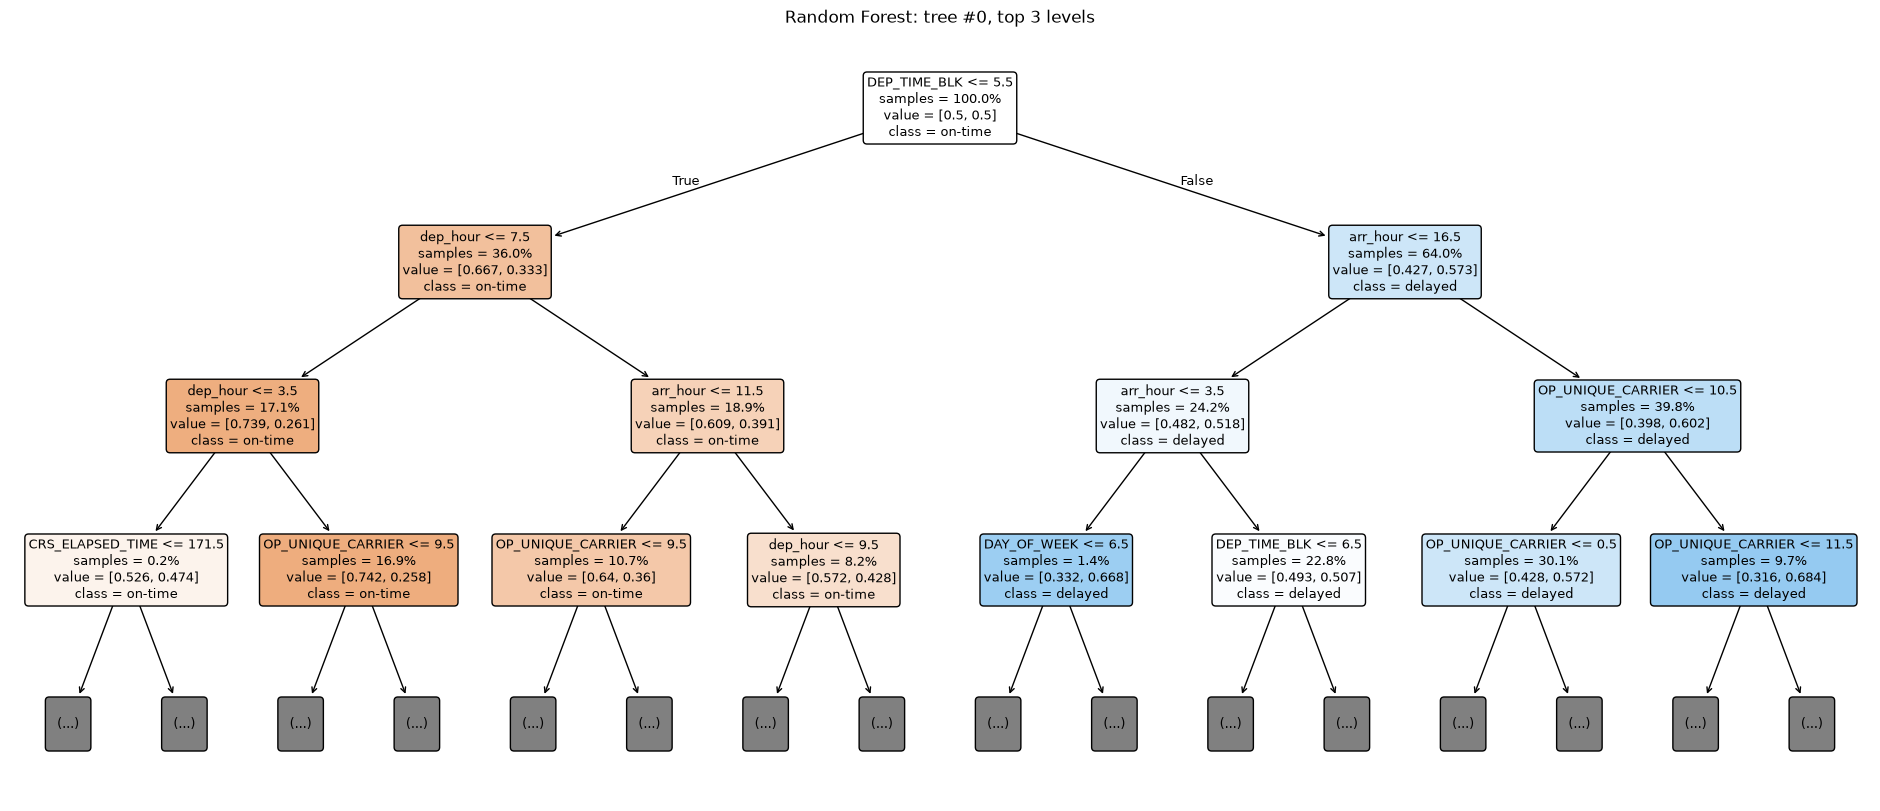

In [13]:
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(final_model.estimators_[0], max_depth=3, feature_names=FEATURES,
          class_names=["on-time", "delayed"], filled=True, rounded=True,
          proportion=True, impurity=False, fontsize=9, ax=ax)
ax.set_title("Random Forest: tree #0, top 3 levels")
plt.show()

In [14]:
# Decode categorical split thresholds shown in the plot (e.g. "ORIGIN <= 120.5")
tree = final_model.estimators_[0].tree_
cat_idx = {FEATURES.index(c): i for i, c in enumerate(CATEGORICAL)}

def node_depths(tree):
    depth, stack = {0: 0}, [0]
    while stack:
        n = stack.pop()
        for child in (tree.children_left[n], tree.children_right[n]):
            if child != -1:
                depth[child] = depth[n] + 1
                stack.append(child)
    return depth

for node, d in sorted(node_depths(tree).items(), key=lambda kv: kv[1]):
    f = tree.feature[node]
    if d < 3 and f in cat_idx:
        cats = final_enc.categories_[cat_idx[f]]
        left = cats[: int(np.floor(tree.threshold[node])) + 1]
        print(f"depth {d}: {FEATURES[f]} <= {tree.threshold[node]:.1f} -> left = "
              f"{list(left[:8])}{' ...' if len(left) > 8 else ''} ({len(left)} values)")

depth 0: DEP_TIME_BLK <= 5.5 -> left = ['0001-0559', '0600-0659', '0700-0759', '0800-0859', '0900-0959', '1000-1059'] (6 values)
depth 2: OP_UNIQUE_CARRIER <= 10.5 -> left = ['AA', 'AS', 'B6', 'DL', 'F9', 'G4', 'MQ', 'NK'] ... (11 values)


## Feature importance

This is impurity-based (mean decrease in Gini). It tends to favor high-cardinality and continuous features, so treat it as a rough ranking.

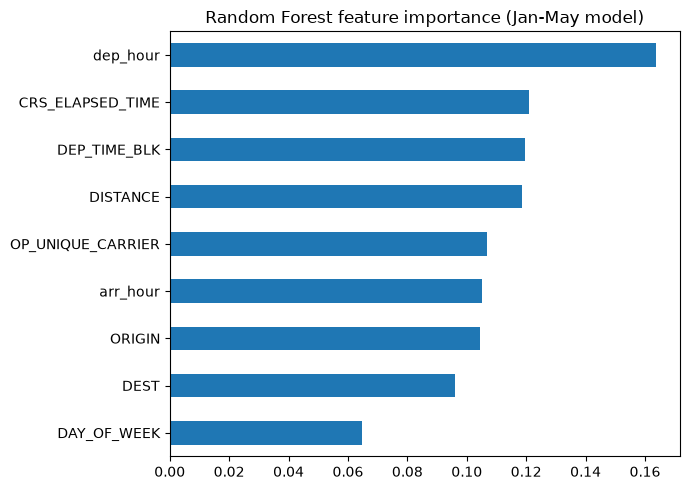

In [15]:
importance = pd.Series(final_model.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 5), title="Random Forest feature importance (Jan-May model)")
plt.tight_layout()
plt.show()

## Tuning parameters (for the report)

| Parameter | Value / searched | Why |
|---|---|---|
| `n_estimators` | 100 (fixed) | number of trees; fixed to keep the grid affordable on ~3M rows |
| `max_features` | searched: `sqrt`, 0.5 | features tried per split; lower means less correlated trees |
| `min_samples_leaf` | searched: 20, 100 | main regularizer; bigger leaves give smoother probabilities |
| `max_depth` | searched: None, 20 | depth cap |
| `max_samples` | 0.25 (fixed) | bootstrap fraction per tree; speed and diversity |
| `class_weight` | `balanced_subsample` (fixed) | ~22% positive class |
| decision threshold | 0.5 | applied to the class-weighted probabilities |
| selection criterion | mean ROC-AUC over Feb–May validation folds | Jun kept as untouched test |

The selected values are in `BEST_PARAMS` above.

In [16]:
pd.Series({k: str(v) for k, v in BEST_PARAMS.items()}, name="selected").to_frame()

,selected
n_estimators,100
class_weight,balanced_subsample
max_samples,0.25
max_features,sqrt
min_samples_leaf,20
max_depth,20


Every constructor argument of the final model, including the ones left at sklearn defaults:

In [17]:
pd.Series({k: str(v) for k, v in final_model.get_params().items()}, name="value").to_frame()

,value
bootstrap,True
ccp_alpha,0.0
class_weight,balanced_subsample
criterion,gini
max_depth,20
max_features,sqrt
max_leaf_nodes,None
max_samples,0.25
min_impurity_decrease,0.0
min_samples_leaf,20


In [18]:
# What the forest actually learned (its "parameters", vs. the hyperparameters above)
depths = [t.get_depth() for t in final_model.estimators_]
leaves = [t.get_n_leaves() for t in final_model.estimators_]
print(f"{len(final_model.estimators_)} trees | depth min/mean/max: {min(depths)}/{np.mean(depths):.1f}/{max(depths)}"
      f" | leaves per tree mean: {np.mean(leaves):,.0f} | total split nodes: {sum(leaves) - len(leaves):,}")

100 trees | depth min/mean/max: 20/20.0/20 | leaves per tree mean: 15,339 | total split nodes: 1,533,810


# Part 2 — Linear Regression (`DEP_DELAY`, minutes)

This uses the same rows, the same 9 features (`FEATURES`) and the same 5 splits (`SPLITS`) as Part 1. Only the encoding changes, because a linear model needs different encoding from a tree:

- **One-hot:** `OP_UNIQUE_CARRIER`, `ORIGIN`, `DEST`, `DEP_TIME_BLK`, `DAY_OF_WEEK`, `dep_hour`, `arr_hour`. Ordinal codes would force a straight-line effect across arbitrary airport or carrier codes. Hours and weekdays are also one-hot, because delay doesn't rise linearly through the day.
- **Rare categories:** levels seen fewer than 50 times in the training fold are grouped into one "infrequent" column. Airports, carriers or hours not seen in training fall into that same column.
- **Numeric:** `CRS_ELAPSED_TIME` and `DISTANCE` are median-imputed (2 rows are missing) and standardized.

Everything is inside one sklearn `Pipeline`, so it's **fit on each training fold only**. Plain least squares has no hyperparameters to tune. (Ridge with alpha=1 gave the same scores to 3 decimals.)

In [19]:
REG_CATEGORICAL = ["DAY_OF_WEEK", "dep_hour", "arr_hour", "DEP_TIME_BLK",
                   "OP_UNIQUE_CARRIER", "ORIGIN", "DEST"]
REG_NUMERIC = ["CRS_ELAPSED_TIME", "DISTANCE"]
assert sorted(REG_CATEGORICAL + REG_NUMERIC) == sorted(FEATURES)   # same features as Part 1

def make_linear_model():
    preprocess = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), REG_CATEGORICAL),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), REG_NUMERIC),
    ])
    return make_pipeline(preprocess, LinearRegression())

def regression_metrics(y_true, pred):
    return {"RMSE": mean_squared_error(y_true, pred) ** 0.5,
            "MAE":  mean_absolute_error(y_true, pred),
            "R²":   r2_score(y_true, pred)}

df[REG_TARGET].describe().round(2)

count    3414526.00
mean          13.83
std           58.75
min          -66.00
25%           -6.00
50%           -2.00
75%           11.00
max         3339.00
Name: DEP_DELAY, dtype: float64

In [20]:
reg_results, reg_baseline = [], []
for i, (train_months, valid_month) in enumerate(SPLITS, start=1):
    train, valid = split(train_months, valid_month)

    lin_model = make_linear_model().fit(train[FEATURES], train[REG_TARGET])
    split_info = {"Split": i, "Train": f"{train_months[0]}-{train_months[-1]}", "Eval": valid_month}
    reg_results.append({**split_info, **regression_metrics(valid[REG_TARGET], lin_model.predict(valid[FEATURES]))})
    # Reference point: always predict the training-fold mean delay
    reg_baseline.append({**split_info, **regression_metrics(valid[REG_TARGET],
                                                            np.full(len(valid), train[REG_TARGET].mean()))})

final_lin_model = lin_model   # trained on Jan-May
reg_results = pd.DataFrame(reg_results).set_index("Split")
reg_baseline = pd.DataFrame(reg_baseline).set_index("Split")

print("Regression  (splits 1-4 = CV on Feb-May, split 5 = Jun test)")
reg_results

Regression  (splits 1-4 = CV on Feb-May, split 5 = Jun test)


,Train,Eval,RMSE,MAE,R²
Split,,,,,
1,1-1,2,54.872872,24.162767,0.008016
2,1-2,3,64.224456,27.122017,0.013458
3,1-3,4,52.854328,23.855837,0.011753
4,1-4,5,54.000059,23.646426,0.017313
5,1-5,6,61.739154,25.998941,0.025699


In [21]:
reg_metrics = ["RMSE", "MAE", "R²"]
pd.DataFrame({
    "CV mean (Feb-May)":         reg_results.loc[1:4, reg_metrics].mean(),
    "CV std":                    reg_results.loc[1:4, reg_metrics].std(),
    "Test (Jun)":                reg_results.loc[5, reg_metrics],
    "Baseline: train mean, CV":  reg_baseline.loc[1:4, reg_metrics].mean(),
    "Baseline: train mean, Jun": reg_baseline.loc[5, reg_metrics],
}).round(4)

,CV mean (Feb-May),CV std,Test (Jun),"Baseline: train mean, CV","Baseline: train mean, Jun"
RMSE,56.4879,5.2235,61.7392,56.9257,62.7167
MAE,24.6968,1.6307,25.9989,25.3859,27.5798
R²,0.0126,0.0039,0.0257,-0.0026,-0.0054


**Reading these numbers:** delay minutes are very heavy-tailed. The median flight leaves 2 minutes *early*, but the max is over 3,000 minutes late. RMSE is driven by those few huge delays, and schedule-only features can't predict them, so R² stays close to 0. Always compare against the "predict the training mean" baseline: that baseline has a slightly negative R², because mean delay shifts from month to month.

### Largest coefficients

One-hot coefficients are in minutes, and numeric ones are per 1 standard deviation. Treat this as a rough ranking, not exact effects. Every group is fully one-hot encoded, and `dep_hour` overlaps almost completely with `DEP_TIME_BLK`, so the time-of-day effect is shared between them in an arbitrary way. The predictions are unaffected; only how the effect is split across coefficients is. The extreme values are mostly small airports, where a handful of flights moves the estimate a lot.

In [22]:
coefs = pd.Series(final_lin_model[-1].coef_, index=final_lin_model[0].get_feature_names_out())
print("intercept:", round(final_lin_model[-1].intercept_, 2))
pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).round(2).to_frame("coef (minutes)")

intercept: 16.71


,coef (minutes)
cat__ORIGIN_JST,39.15
cat__DEST_VCT,35.85
cat__ORIGIN_HTS,34.66
cat__DEST_CMX,32.60
cat__DEST_JST,32.55
cat__DEST_LWB,27.89
cat__ORIGIN_PAH,26.88
cat__ORIGIN_MQT,25.78
cat__DEST_PAH,25.07
cat__DEST_IMT,22.51
